In [2]:
from scipy.interpolate import interp1d
from scipy.integrate import solve_ivp
from scipy.optimize import root
import matplotlib.pyplot as plt
from scipy.interpolate import PchipInterpolator
import math
import numpy as np
# Fundamental constants in SI
G = 6.67430e-11            # gravitational constant [m^3 kg^-1 s^-2]
c = 2.99792458e8           # speed of light [m s^-1]
hbar = 1.054571817e-34     # reduced Planck constant [J s]
M_sun = 1.98847e30         # solar mass [kg]


# Basic unit conversions
eV_to_J = 1.602176634e-19
MeV_to_J = 1.0e6 * eV_to_J

J_to_eV = 1.0 / eV_to_J
J_to_MeV = 1.0 / MeV_to_J

fm_to_m = 1.0e-15
m_to_fm = 1.0 / fm_to_m

km_to_m = 1.0e3
m_to_km = 1.0 / km_to_m

def kg_to_MeV_c2(m_kg):
    return m_kg * c**2 * J_to_MeV


def MeV_c2_to_kg(m_MeV):
    return m_MeV * MeV_to_J / c**2

MeV_fm3_to_J_m3 = MeV_to_J / fm_to_m**3
J_m3_to_MeV_fm3 = 1.0 / MeV_fm3_to_J_m3

def MeV_fm3_to_SI(x):
    return x * MeV_fm3_to_J_m3
def SI_to_MeV_fm3(x):
    return x * J_m3_to_MeV_fm3




In [3]:
# Boundary values from the 2014 paper
#mu in MeV, n0 in fm, P in Mev/fm^3,
n0 = 0.16
n_begin = 1.1 * n0
mu_begin = 977.5
P_begin = 3.542
Gamma_regions = np.array([4.021,1.195])
mu_transition = 1350.0   
mu_end = 2600.0      


gamma1 = Gamma_regions[0]
gamma2 = Gamma_regions[1]

kappa1 = (P_begin/ n_begin**gamma1)
#Transition density by inverting equ 1 
n_transition = (n_begin**(gamma1 - 1.0) + ((gamma1 - 1.0)/ (kappa1 * gamma1))* (mu_transition - mu_begin))**(1.0 / (gamma1 - 1.0))
# Pressure at transition as a result
P_transition = (kappa1 * n_transition**gamma1)
kappa2 = (P_transition/ n_transition**gamma2)

kappa_regions = np.array([kappa1,kappa2])
n_breaks = np.array([n_transition])
P_breaks = np.array([P_transition])
n_start_regions = np.array([n_begin,n_transition])
mu_start_regions = np.array([mu_begin,mu_transition])
print("kappa1 =", kappa1)
print("Transition density =",n_transition,"fm^-3")
print("Transition density / n0 =", n_transition / n0)
print("Transition pressure =",P_transition,"MeV/fm^3")
print("kappa2 =",kappa2)

def poly_density_region(n):
    return np.searchsorted(n_breaks,n,side="right")
def poly_pressure_region(P_MeV):
    return np.searchsorted(P_breaks,P_MeV,side="right")

kappa1 = 3828.618729545717
Transition density = 0.43044306598334575 fm^-3
Transition density / n0 = 2.6902691623959107
Transition pressure = 129.12704549427107 MeV/fm^3
kappa2 = 353.58019697289467


In [4]:
# EOS for : Pressure as a function of baryon dfensity
def poly_pressure_n(n):

    n = np.asarray(n)
    region = poly_density_region(n)
    kappa = kappa_regions[region]
    gamma = Gamma_regions[region]
    #equ 6
    P = (kappa* n**gamma)
    return P

# Rearranging equation 7 for the Baryon Chemical Potential

def poly_mu_n(n):

    n = np.asarray(n)
    region = poly_density_region(n)
    gamma = Gamma_regions[region]
    kappa = kappa_regions[region]
    n_start = n_start_regions[region]
    mu_start = mu_start_regions[region]
    mu = (mu_start+ (gamma* kappa/ (gamma - 1.0)) * ( n**(gamma - 1.0) - n_start**(gamma - 1.0)))
    return mu

# using E = TS - PV + muN, set T = 0 in our case (0 TEMPERATURE)

def poly_energy_n(n):
    P = poly_pressure_n(n)
    mu = poly_mu_n(n)
    E = (mu * n- P)
    return E


def poly_cs2_n(n):

    n = np.asarray(n)

    region = poly_density_region(n)

    gamma = Gamma_regions[region]
    P = poly_pressure_n(n)

    mu = poly_mu_n(n)
    cs2 = (gamma* P/ (mu* n))


    return cs2




In [5]:

def poly_n_from_P_MeV(P_MeV):

    P_MeV = np.asarray(P_MeV)

    region = poly_pressure_region(P_MeV)
    kappa = kappa_regions[region]

    gamma = Gamma_regions[region]
    n = (P_MeV/ kappa)**(1.0 / gamma)

    return n


def poly_e_density(P):
    P_MeV = SI_to_MeV_fm3(P)
    n = poly_n_from_P_MeV(P_MeV)
    E_MeV = poly_energy_n(n)
    E_SI = MeV_fm3_to_SI(E_MeV)
    return E_SI

In [6]:
# ============================================================
# CHECK AGAINST REPRESENTATIVE EOS II
# ============================================================

n_test = (np.array([1.1,1.5,2.1,2.5,2.7,3.5,4.5])* n0)


P_test = poly_pressure_n(n_test)
E_test = poly_energy_n(n_test)
mu_test = poly_mu_n(n_test)

cs2_test = poly_cs2_n(n_test)
for i in range(len(n_test)):

    print(
        f"n/n0 = {n_test[i]/n0:.1f}, "
        f"P = {P_test[i]:.3f}, "
        f"E = {E_test[i]:.3f}, "
        f"mu_B = {mu_test[i]/1000:.4f} GeV, "
        f"cs2 = {cs2_test[i]:.3f}"
    )

n/n0 = 1.1, P = 3.542, E = 168.498, mu_B = 0.9775 GeV, cs2 = 0.083
n/n0 = 1.5, P = 12.327, E = 232.252, mu_B = 1.0191 GeV, cs2 = 0.203
n/n0 = 2.1, P = 47.693, E = 335.227, mu_B = 1.1396 GeV, cs2 = 0.501
n/n0 = 2.5, P = 96.145, E = 412.111, mu_B = 1.2706 GeV, cs2 = 0.761
n/n0 = 2.7, P = 129.685, E = 454.074, mu_B = 1.3513 GeV, cs2 = 0.265
n/n0 = 3.5, P = 176.837, E = 633.364, mu_B = 1.4468 GeV, cs2 = 0.261
n/n0 = 4.5, P = 238.781, E = 872.887, mu_B = 1.5440 GeV, cs2 = 0.257


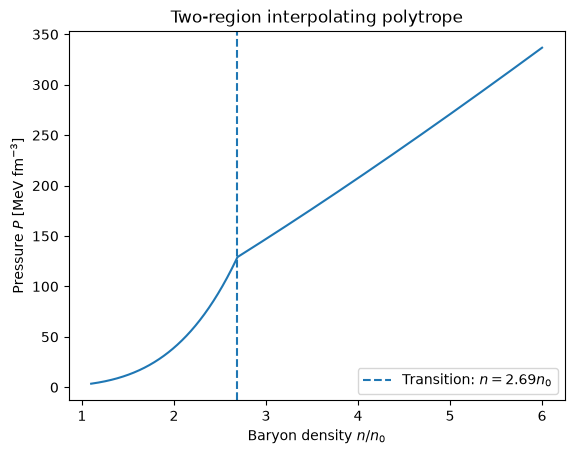

In [7]:

n_plot = np.linspace(n_begin, 6.0*n0, 1000)
P_plot = poly_pressure_n(n_plot)
plt.plot(n_plot/n0, P_plot)

plt.axvline(n_transition/n0, linestyle="--",label=fr"Transition: $n={n_transition/n0:.2f}n_0$")

plt.xlabel(r"Baryon density $n/n_0$")
plt.ylabel(r"Pressure $P$ [MeV fm$^{-3}$]")
plt.title("Two-region interpolating polytrope")
plt.legend()
plt.show()

In [8]:
# Low density Region EOS:
from scipy.optimize import brentq, root

T0 = 36.84
alpha = 5.87
eta = 3.81
gamma_chi = 4/3
hbarc = 197.3269804
mN = 939.0                  # MeV

# electron chemical potential
def mu_electron(n, x):
    return hbarc*(3*np.pi**2*x*n)**(1/3)

def deps_dx(n, x, alphaL, etaL):
    nb = n/n0
    A = 2*alpha - 4*alphaL
    B = 2*eta - 4*etaL

    return T0*((x**(2/3)-(1-x)**(2/3))*(2*nb)**(2/3)
               - A*(1-2*x)*nb
               + B*(1-2*x)*nb**gamma_chi)

def beta_x(n, alphaL, etaL):
    f = lambda x: deps_dx(n,x,alphaL,etaL) + mu_electron(n,x)
    return brentq(f, 1e-8, 0.499999)


In [9]:
# Nuclear equations for ep and P
def chiral_eps(n, x, alphaL, etaL):
    nb = n/n0

    kinetic = (3/5)*(x**(5/3)+(1-x)**(5/3))*(2*nb)**(2/3)

    A = ((2*alpha-4*alphaL)*x*(1-x) + alphaL)
    B = ((2*eta-4*etaL)*x*(1-x) + etaL)

    return T0*(kinetic - A*nb + B*nb**gamma_chi)
#Baryonic Pressure and electron pressure
def chiral_pressure(n, alphaL, etaL):
    x = beta_x(n, alphaL, etaL)
    nb = n/n0

    A = ((2*alpha-4*alphaL)*x*(1-x) + alphaL)
    B = ((2*eta-4*etaL)*x*(1-x) + etaL)

    Pb = n0*T0*((1/5)*(x**(5/3)+(1-x)**(5/3))*(2*nb)**(5/3)
                - A*nb**2 + gamma_chi*B*nb**(gamma_chi+1))

    mu_e = mu_electron(n,x)
    Pe = 0.25*mu_e*x*n

    return Pb + Pe

def chiral_energy(n, alphaL, etaL):
    x = beta_x(n, alphaL, etaL)
    eps = chiral_eps(n,x,alphaL,etaL)

    mu_e = mu_electron(n,x)
    Ee = 0.75*mu_e*x*n

    return n*(mN + eps) + Ee
    

In [10]:
#Restricting the region of our values for al between 1.18 - 1.59 and nl between 0.64 - 1.11
P_target = 3.542
mu_target = 977.5

def match_chiral(z):
    alphaL, etaL = z

    P = chiral_pressure(n_begin, alphaL, etaL)
    E = chiral_energy(n_begin, alphaL, etaL)
    mu = (E + P)/n_begin

    return [P-P_target, mu-mu_target]

alphaL, etaL = root(match_chiral, [1.5,1.05]).x

print("alphaL =", alphaL)
print("etaL =", etaL)
P_chi_end = chiral_pressure(n_begin, alphaL, etaL)
E_chi_end = chiral_energy(n_begin, alphaL, etaL)
mu_chi_end = (E_chi_end + P_chi_end)/n_begin

print("P =", P_chi_end)
print("E =", E_chi_end)
print("mu_B =", mu_chi_end)

alphaL = 1.4641889049557169
etaL = 1.0214198935378929
P = 3.54200000000025
E = 168.49800000000087
mu_B = 977.5000000000064


In [11]:
def combined_pressure_n(n):
    if np.isscalar(n):
        return chiral_pressure(n,alphaL,etaL) if n <= n_begin else poly_pressure_n(n)

    return np.array([
        chiral_pressure(ni,alphaL,etaL) if ni <= n_begin else poly_pressure_n(ni)
        for ni in n
    ])


def combined_energy_n(n):
    if np.isscalar(n):
        return chiral_energy(n,alphaL,etaL) if n <= n_begin else poly_energy_n(n)

    return np.array([
        chiral_energy(ni,alphaL,etaL) if ni <= n_begin else poly_energy_n(ni)
        for ni in n
    ])

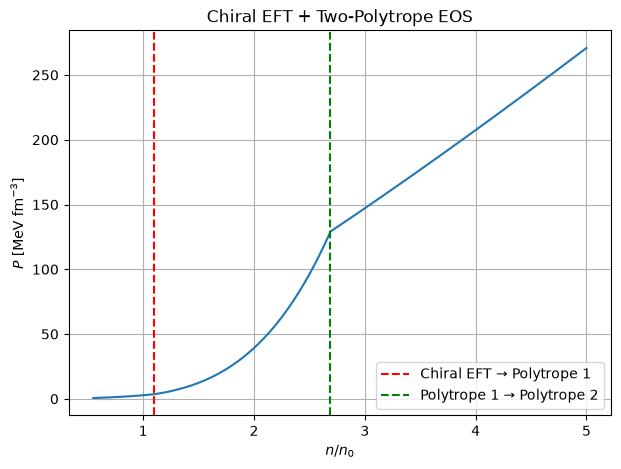

In [12]:
n_plot = np.linspace(0.55*n0, 5*n0, 700)

P_plot = combined_pressure_n(n_plot)
E_plot = combined_energy_n(n_plot)

plt.figure(figsize=(7,5))
plt.plot(n_plot/n0, P_plot)

plt.axvline(1.1, color="red", linestyle="--",
            label="Chiral EFT → Polytrope 1")

plt.axvline(n_transition/n0, color="green", linestyle="--",
            label="Polytrope 1 → Polytrope 2")

plt.xlabel(r"$n/n_0$")
plt.ylabel(r"$P$ [MeV fm$^{-3}$]")
plt.title("Chiral EFT + Two-Polytrope EOS")
plt.grid()
plt.legend()
plt.show()

In [13]:
# PQCD High density Region
# pQCD parameters for EOS II

X_pqcd = 1.2

c1 = 0.9008
d1 = 0.5034
d2 = 1.452
nu1 = 0.3553
nu2 = 0.9101

hbarc_GeVfm = 0.1973269804
mu_pqcd_begin = 2600.0 

def pqcd_ab(X):
    a = d1*X**(-nu1)
    b = d2*X**(-nu2)
    return a, b
#PSB term of noninteracting massless quark flavours
def pqcd_pressure_mu(muB, X=X_pqcd):
    u = muB/1000.0                     # MeV -> GeV
    a, b = pqcd_ab(X)

    P_SB = (3/(4*np.pi**2))*(u/3)**4
    P_nat = P_SB*(c1 - a/(u-b))

    return P_nat*1000/hbarc_GeVfm**3

# Baryon Number Density
def pqcd_number_density_mu(muB, X=X_pqcd):
    u = muB/1000.0
    a, b = pqcd_ab(X)

    C = 1/(108*np.pi**2)
    f = c1 - a/(u-b)
    fp = a/(u-b)**2

    return C*(4*u**3*f + u**4*fp)/hbarc_GeVfm**3

def pqcd_energy_mu(muB, X=X_pqcd):
    P = pqcd_pressure_mu(muB, X)
    n = pqcd_number_density_mu(muB, X)
    return muB*n - P



In [14]:
#SOS CHECK 
def pqcd_cs2_mu(muB, X=X_pqcd):
    u = muB/1000.0
    a, b = pqcd_ab(X)

    C = 1/(108*np.pi**2)
    f = c1 - a/(u-b)
    fp = a/(u-b)**2
    fpp = -2*a/(u-b)**3

    n = pqcd_number_density_mu(muB, X)

    dn_du = C*(12*u**2*f + 8*u**3*fp + u**4*fpp)/hbarc_GeVfm**3

    return n/(u*dn_du)
    

In [15]:
# End of second polytrope at mu_B = 2.6 GeV

n_poly_end = (n_transition**(gamma2-1)+ (gamma2-1)/(kappa2*gamma2)*(mu_end-mu_transition))**(1/(gamma2-1))

P_poly_end = poly_pressure_n(n_poly_end)
E_poly_end = poly_energy_n(n_poly_end)

# pQCD values
P_qcd_end = pqcd_pressure_mu(mu_end)
n_qcd_end = pqcd_number_density_mu(mu_end)
E_qcd_end = pqcd_energy_mu(mu_end)

print("Second polytrope:")
print("n =", n_poly_end, "fm^-3")
print("P =", P_poly_end, "MeV/fm^3")
print("E =", E_poly_end, "MeV/fm^3")

print("\npQCD:")
print("n =", n_qcd_end, "fm^-3")
print("P =", P_qcd_end, "MeV/fm^3")
print("E =", E_qcd_end, "MeV/fm^3")

Second polytrope:
n = 6.155707819073662 fm^-3
P = 3102.238196638293 MeV/fm^3
E = 12902.60213295323 MeV/fm^3

pQCD:
n = 6.178894510182841 fm^-3
P = 3104.5637057821496 MeV/fm^3
E = 12960.562020693238 MeV/fm^3


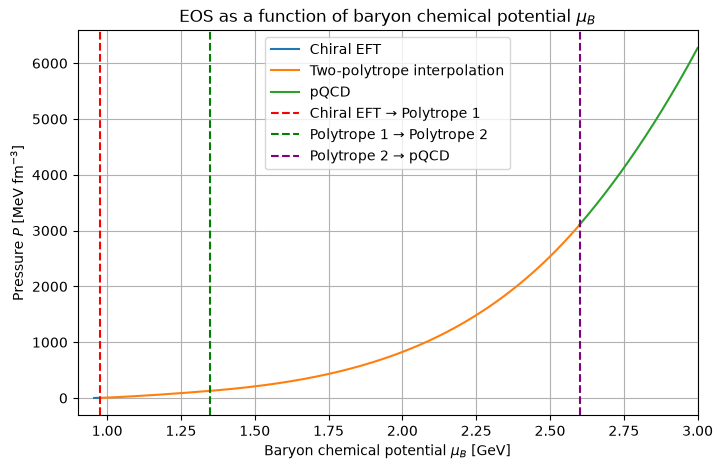

In [16]:
# Chiral EFT
n_chi = np.linspace(0.55*n0, n_begin, 250)
P_chi = np.array([chiral_pressure(n, alphaL, etaL) for n in n_chi])
E_chi = np.array([chiral_energy(n, alphaL, etaL) for n in n_chi])
mu_chi = (E_chi + P_chi)/n_chi

# Two polytropes
n_poly = np.linspace(n_begin, n_poly_end, 700)
P_poly = poly_pressure_n(n_poly)
mu_poly = poly_mu_n(n_poly)

# pQCD
mu_qcd = np.linspace(mu_end, 3000, 300)
P_qcd = pqcd_pressure_mu(mu_qcd)

plt.figure(figsize=(8,5))

plt.plot(mu_chi/1000, P_chi, label="Chiral EFT")
plt.plot(mu_poly/1000, P_poly, label="Two-polytrope interpolation")
plt.plot(mu_qcd/1000, P_qcd, label="pQCD")

plt.axvline(mu_begin/1000, color="red", linestyle="--",
            label="Chiral EFT → Polytrope 1")
plt.axvline(mu_transition/1000, color="green", linestyle="--",
            label="Polytrope 1 → Polytrope 2")
plt.axvline(mu_end/1000, color="purple", linestyle="--",
            label="Polytrope 2 → pQCD")

plt.xlabel(r"Baryon chemical potential $\mu_B$ [GeV]")
plt.ylabel(r"Pressure $P$ [MeV fm$^{-3}$]")
plt.title(r"EOS as a function of baryon chemical potential $\mu_B$")
plt.xlim(0.9, 3.0)
plt.grid()
plt.legend()
plt.show()

In [17]:
n_chi_grid = np.linspace(0.55*n0, n_begin, 400)
P_chi_grid = np.array([chiral_pressure(n,alphaL,etaL) for n in n_chi_grid])
E_chi_grid = np.array([chiral_energy(n,alphaL,etaL) for n in n_chi_grid])
# ESTIMATES ENERGY DENSITY FROM PRESSURE
chi_E_of_P = PchipInterpolator(P_chi_grid, E_chi_grid,extrapolate=False)
# IN BOTH REGIONS WE CANT SOLEV ANALYTICALLY, WE USE INTERPLOTATION TECHNIQUES FOR ESTIMATION
mu_qcd_grid = np.linspace(mu_end, 6000.0, 800)
P_qcd_grid = pqcd_pressure_mu(mu_qcd_grid)
E_qcd_grid = pqcd_energy_mu(mu_qcd_grid)
qcd_E_of_P = PchipInterpolator(P_qcd_grid, E_qcd_grid,extrapolate=False)

P_chi_min = P_chi_grid[0]
P_chi_end = P_begin
P_poly_end = poly_pressure_n(n_poly_end)
P_qcd_start = pqcd_pressure_mu(mu_end)

print("Chiral minimum P =", P_chi_min)
print("Chiral → poly P =", P_chi_end)
print("Poly end P =", P_poly_end)
print("pQCD start P =", P_qcd_start)






Chiral minimum P = 0.6286781589047191
Chiral → poly P = 3.542
Poly end P = 3102.238196638293
pQCD start P = 3104.5637057821496


In [18]:
# Piecewise full density equation
def full_e_density(P):
    P_MeV = SI_to_MeV_fm3(P)

    if P_MeV < P_chi_min:
        raise ValueError("Pressure is below current chiral-EFT range.")

    if P_MeV <= P_chi_end:
        E_MeV = float(chi_E_of_P(P_MeV))

    elif P_MeV < P_qcd_start:
        n = poly_n_from_P_MeV(P_MeV)
        E_MeV = poly_energy_n(n)

    else:
        E_MeV = float(qcd_E_of_P(P_MeV))

    return MeV_fm3_to_SI(E_MeV)



In [19]:
P_surface = MeV_fm3_to_SI(P_chi_min)
def tov_equations(r,y):
    m,P = y
    if r <= 0.0:
        print("TOV equations cannot be evaluated at singularity.")

    if P <= P_surface:
        return [0.0, 0.0]
    E = full_e_density(P)
    
    dmdr = 4.0 * np.pi * r**2 * E/ c**2
    t1 = G * E * m / (c**2 * r**2)

    t2 = 1.0 + P / E

    t3 = 1.0 + (4.0 * np.pi * r**3 * P) / (m * c**2)

    t4 = 1.0 - (2.0 * G * m) / (c**2 * r)

    dPdr = -t1 * t2 * t3 / t4
    return [dmdr, dPdr]



In [20]:
P_surface = MeV_fm3_to_SI(P_chi_min)

def surface_event(r, y):
    return y[1] - P_surface

surface_event.terminal = True
surface_event.direction = -1

from scipy.integrate import solve_ivp
 # in mev
def solve_star(P_c_MeV, return_profile=False):
    P_c = MeV_fm3_to_SI(P_c_MeV)
    E_c = full_e_density(P_c)

    r_start = 1e-3
    m_start = (4*np.pi/3)*r_start**3*E_c/c**2

    sol = solve_ivp(
        tov_equations,
        [r_start, 5e4],
        [m_start, P_c],
        events=surface_event,
        rtol=1e-6,
        max_step=20
    )

    if len(sol.t_events[0]) == 0:
        if return_profile:
            return np.nan, np.nan, None
        return np.nan, np.nan

    R = sol.t_events[0][0]
    M = sol.y_events[0][0][0]

    if return_profile:
        return M/M_sun, R/1000, sol

    return M/M_sun, R/1000

M_test, R_test = solve_star(500.0)

print("Mass =", M_test, "M_sun")
print("Radius =", R_test, "km")

Mass = 2.2746248587770475 M_sun
Radius = 11.797368947945916 km


## EOS III alongside EOS II: same analytical stiff nuclear EOS
EOS III has the same hard nuclear anchor, but uses Table 1 of Kurkela et al. (2014),
changes the interpolation and the pQCD scale:

| Parameter | EOS II | EOS III |
|---|---:|---:|
| Gamma 1 | 4.021 | 7.368 |
| Gamma 2 | 1.195 | 1.415 |
| Joining chemical potential [MeV] | 1350 | 1125 |
| pQCD scale X | 1.2 | 1.9 |

The starting values n=1.1n0, P=3.542 MeV/fm^3, mu=977.5 MeV and the
high-density matching chemical potential 2600 MeV stay the same.


In [21]:
# EOS III parameters: the analytical chiral functions above are reused.
Gamma_III = np.array([7.368, 1.415])
mu_transition_III = 1125.0       # MeV
mu_end_III = 2600.0              # MeV
X_III = 1.9

kappa1_III = P_begin / n_begin**Gamma_III[0]

n_transition_III = (
    n_begin**(Gamma_III[0] - 1)
    + (Gamma_III[0] - 1) * (mu_transition_III - mu_begin)
    / (Gamma_III[0] * kappa1_III)
)**(1 / (Gamma_III[0] - 1))

P_transition_III = kappa1_III * n_transition_III**Gamma_III[0]
kappa2_III = P_transition_III / n_transition_III**Gamma_III[1]

kappa_III = np.array([kappa1_III, kappa2_III])
n_start_III = np.array([n_begin, n_transition_III])
mu_start_III = np.array([mu_begin, mu_transition_III])

print('EOS III joining density:', n_transition_III/n0, 'n0')
print('EOS III joining pressure:', P_transition_III, 'MeV/fm^3')

EOS III joining density: 1.504131892959913 n0
EOS III joining pressure: 35.52302248945443 MeV/fm^3


### Calculate EOS III pressure, chemical potential and energy density
We use exactly the same polytropic expressions as for EOS II. `searchsorted`
selects segment 0 or 1. The chemical-potential integration constants enforce
continuity at the segment join, and total energy density follows from
epsilon = mu*n - P. All quantities here use MeV and fm units.

In [22]:
def poly_pressure_III(n):
    n = np.asarray(n)
    region = np.searchsorted([n_transition_III], n, side='right')
    return kappa_III[region] * n**Gamma_III[region]


def poly_mu_III(n):
    n = np.asarray(n)
    region = np.searchsorted([n_transition_III], n, side='right')
    gamma = Gamma_III[region]
    kappa = kappa_III[region]
    return (
        mu_start_III[region]
        + gamma*kappa/(gamma - 1)
        * (n**(gamma - 1) - n_start_III[region]**(gamma - 1))
    )


def poly_energy_III(n):
    return poly_mu_III(n)*n - poly_pressure_III(n)


def poly_n_from_pressure_III(P_MeV):
    region = np.searchsorted([P_transition_III], P_MeV, side='right')
    return (P_MeV/kappa_III[region])**(1/Gamma_III[region])


n_poly_end_III = (
    n_transition_III**(Gamma_III[1] - 1)
    + (Gamma_III[1] - 1)*(mu_end_III - mu_transition_III)
    / (Gamma_III[1]*kappa2_III)
)**(1/(Gamma_III[1] - 1))

### Add the pQCD branch and reuse the same nuclear interpolation
Pass X=1.9 explicitly to the existing pQCD functions. Simply changing a global
X variable would not update their captured default arguments.
The low-density branch below uses the very same `chi_E_of_P` interpolator as
EOS II. There is no refit or replacement of the analytical stiff nuclear EOS.
Like the existing EOS II implementation, the rounded published parameters
give an approximate pQCD endpoint match; we print its residual, not hide it.

In [23]:
mu_qcd_grid_III = np.linspace(mu_end_III, 6000.0, 800)
P_qcd_grid_III = pqcd_pressure_mu(mu_qcd_grid_III, X=X_III)
E_qcd_grid_III = pqcd_energy_mu(mu_qcd_grid_III, X=X_III)

qcd_E_of_P_III = PchipInterpolator(
    P_qcd_grid_III, E_qcd_grid_III, extrapolate=False
)
P_qcd_start_III = float(P_qcd_grid_III[0])


def full_e_density_III(P):
    """SI pressure [Pa] in; total energy density [J/m^3] out."""
    pressure = float(SI_to_MeV_fm3(P))
    if pressure < P_chi_min*(1 - 1e-12):
        raise ValueError('Pressure is below the shared nuclear EOS table.')
    # Allow only roundoff at the lower endpoint, never physical extrapolation.
    pressure = max(pressure, P_chi_min)

    if pressure <= P_begin:
        energy = float(chi_E_of_P(pressure))
    elif pressure < P_qcd_start_III:
        density = poly_n_from_pressure_III(pressure)
        energy = float(poly_energy_III(density))
    else:
        energy = float(qcd_E_of_P_III(pressure))

    if not np.isfinite(energy):
        raise ValueError('Pressure is outside the EOS III interpolation domain.')
    return MeV_fm3_to_SI(energy)


print('EOS III poly endpoint pressure:', float(poly_pressure_III(n_poly_end_III)))
print('EOS III pQCD start pressure:', P_qcd_start_III)
print('Endpoint pressure difference [MeV/fm^3]:',
      float(poly_pressure_III(n_poly_end_III))-P_qcd_start_III)

EOS III poly endpoint pressure: 3779.7102553710415
EOS III pQCD start pressure: 3777.2724788401265
Endpoint pressure difference [MeV/fm^3]: 2.4377765309150163


### Integrate EOS III with the same TOV equations and outer cutoff
The state is [enclosed mass, pressure] in SI units. We start at a tiny positive
radius using the same central mass expansion as the original solver.
The integration stops at the SAME pressure `P_surface` used by EOS II.
Because this pressure corresponds to n=0.55n0 rather than P=0, the reported
radii omit lower-density outer layers. These are comparisons of the existing
notebook models, not exact reproductions of published complete-star radii.

In [24]:
def tov_equations_III(r, y):
    mass, pressure = y
    if pressure <= P_surface:
        return [0.0, 0.0]

    energy = full_e_density_III(pressure)
    dmdr = 4*np.pi*r**2*energy/c**2
    dPdr = (
        -G*(energy + pressure)*(mass + 4*np.pi*r**3*pressure/c**2)
        / (c**2*r**2*(1 - 2*G*mass/(r*c**2)))
    )
    return [dmdr, dPdr]


def surface_event_III(r, y):
    return y[1] - P_surface


surface_event_III.terminal = True
surface_event_III.direction = -1


def solve_star_III(P_c_MeV, return_profile=False):
    central_pressure = MeV_fm3_to_SI(P_c_MeV)
    central_energy = full_e_density_III(central_pressure)
    r_start_III = 1e-3
    mass_start = 4*np.pi*r_start_III**3*central_energy/(3*c**2)

    solution = solve_ivp(
        tov_equations_III, [r_start_III, 5e4],
        [mass_start, central_pressure], events=surface_event_III,
        rtol=1e-6, max_step=20
    )
    if not solution.success or len(solution.t_events[0]) == 0:
        raise RuntimeError('EOS III integration did not reach the outer cutoff.')

    radius = solution.t_events[0][0]/1000
    mass = solution.y_events[0][0][0]/M_sun
    if return_profile:
        return mass, radius, solution
    return mass, radius

## EOS I: analytical soft nuclear input
EOS I uses the same nuclear energy expression and beta-equilibrium solve as
EOS II/III, but different fitted alpha_L and eta_L. We fit the soft anchor
at n=1.1n0: P=2.163 MeV/fm^3 and mu_B=965.7 MeV. No existing hard-EOS
parameter is overwritten. Every new name carries the suffix `_I`.

The full EOS I also uses Gamma=(3.192,1.024), mu_join=1650 MeV, X=1.2,
and mu_end=2600 MeV (Kurkela et al. 2014, Table 1, arXiv:1402.6618).
The analytical soft nuclear fit is approximate between the matching points;
its comparison with the seven soft rows of Hebeler et al. 2013 Table 5 is
shown below. It is not the entire 2013 soft EOS continued to high density.

In [25]:
# Fit just the two soft nuclear coefficients, using the existing functions.
n_begin_I = 1.1*n0
P_begin_I = 2.163
mu_begin_I = 965.7


def match_chiral_I(parameters):
    alpha_soft, eta_soft = parameters
    pressure = chiral_pressure(n_begin_I, alpha_soft, eta_soft)
    energy = chiral_energy(n_begin_I, alpha_soft, eta_soft)
    chemical_potential = (energy + pressure)/n_begin_I
    return [pressure - P_begin_I, chemical_potential - mu_begin_I]


fit_I = root(match_chiral_I, [1.2, 0.65])
if not fit_I.success:
    raise RuntimeError(fit_I.message)
np.testing.assert_allclose(fit_I.fun, 0, atol=1e-8)
alphaL_I, etaL_I = fit_I.x


def chiral_pressure_I(n):
    return chiral_pressure(n, alphaL_I, etaL_I)


def chiral_energy_I(n):
    return chiral_energy(n, alphaL_I, etaL_I)


def chiral_mu_I(n):
    return (chiral_energy_I(n) + chiral_pressure_I(n))/n


print('Soft nuclear fit: alphaL_I =', alphaL_I, ', etaL_I =', etaL_I)
print('At 1.1n0: P =', chiral_pressure_I(n_begin_I),
      'E =', chiral_energy_I(n_begin_I),
      'mu_B =', chiral_mu_I(n_begin_I))

Soft nuclear fit: alphaL_I = 1.2153849129191907 , etaL_I = 0.6640439286697408
At 1.1n0: P = 2.1629999999995633 E = 167.80020000000013 mu_B = 965.6999999999981


### Check the fitted soft model against the low-density numerical reference
These are the seven soft entries of Hebeler et al. (2013), Table 5, restricted
to n<=1.1n0. The pressure/energy units are MeV/fm^3. Percent differences use
100*(analytical-reference)/reference. Only the anchor is imposed exactly;
the other rows test the shape of the analytical parameterization.

In [26]:
import pandas as pd

soft_reference_I = np.array([
    [0.5792, 0.4470, 87.90],
    [0.7124, 0.7162, 108.20],
    [0.7861, 0.9094, 119.50],
    [0.8646, 1.1540, 131.50],
    [0.9483, 1.4640, 144.40],
    [1.0371, 1.8510, 158.00],
    [1.1000, 2.1630, 167.80]
])
soft_n_I = soft_reference_I[:, 0]*n0
soft_P_analytic_I = np.array([chiral_pressure_I(n) for n in soft_n_I])
soft_E_analytic_I = np.array([chiral_energy_I(n) for n in soft_n_I])
soft_check_I = pd.DataFrame({
    'n/n0': soft_reference_I[:, 0],
    'P reference': soft_reference_I[:, 1],
    'P analytical': soft_P_analytic_I,
    'P difference [%]': 100*(soft_P_analytic_I/soft_reference_I[:, 1] - 1),
    'E reference': soft_reference_I[:, 2],
    'E analytical': soft_E_analytic_I,
    'E difference [%]': 100*(soft_E_analytic_I/soft_reference_I[:, 2] - 1)
})
display(soft_check_I.round(6))

,n/n0,P reference,P analytical,P difference [%],E reference,E analytical,E difference [%]
0,0.5792,0.4470,0.464622,3.942260,87.9,87.884606,-0.017513
1,0.7124,0.7162,0.734691,2.581868,108.2,108.229612,0.027368
2,0.7861,0.9094,0.927305,1.968892,119.5,119.511660,0.009757
3,0.8646,1.1540,1.170448,1.425340,131.5,131.550120,0.038114
4,0.9483,1.4640,1.476255,0.837104,144.4,144.412448,0.008621
5,1.0371,1.8510,1.856768,0.311631,158.0,158.090471,0.057260
6,1.1000,2.1630,2.163000,-0.000000,167.8,167.800200,0.000119


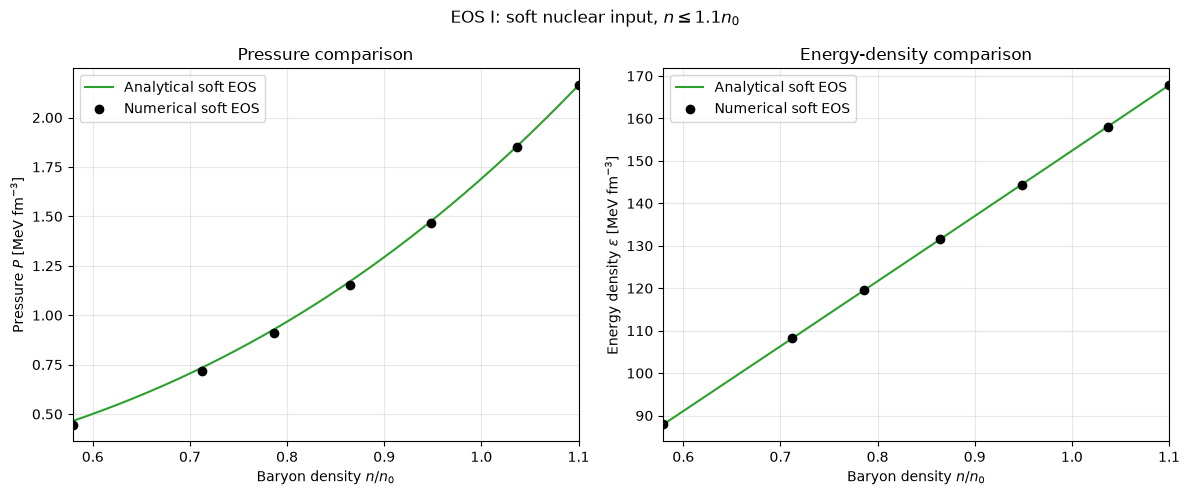

In [44]:
import numpy as np
import matplotlib.pyplot as plt

# Numerical soft EOS from Table 5:
# Columns: n/n0, pressure [MeV/fm^3], energy density [MeV/fm^3].
reference_soft = np.array([
    [0.5792, 0.4470,  87.90],
    [0.7124, 0.7162, 108.20],
    [0.7861, 0.9094, 119.50],
    [0.8646, 1.1540, 131.50],
    [0.9483, 1.4640, 144.40],
    [1.0371, 1.8510, 158.00],
    [1.1000, 2.1630, 167.80]
])

# Evaluate the analytical EOS on a smooth density grid.
n_ratio = np.linspace(reference_soft[0, 0], 1.1, 300)
n_values = n_ratio * n0

P_analytical = np.array([chiral_pressure_I(n) for n in n_values])
E_analytical = np.array([chiral_energy_I(n) for n in n_values])

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Pressure comparison.
axes[0].plot(
    n_ratio, P_analytical, color="C2",
    label="Analytical soft EOS"
)
axes[0].scatter(
    reference_soft[:, 0], reference_soft[:, 1],
    color="black", marker="o", zorder=3,
    label="Numerical soft EOS"
)
axes[0].set_ylabel(r"Pressure $P$ [MeV fm$^{-3}$]")
axes[0].set_title("Pressure comparison")

# Total energy-density comparison.
axes[1].plot(
    n_ratio, E_analytical, color="C2",
    label="Analytical soft EOS"
)
axes[1].scatter(
    reference_soft[:, 0], reference_soft[:, 2],
    color="black", marker="o", zorder=3,
    label="Numerical soft EOS"
)
axes[1].set_ylabel(r"Energy density $\varepsilon$ [MeV fm$^{-3}$]")
axes[1].set_title("Energy-density comparison")

# Formatting shared by both plots.
for ax in axes:
    ax.set_xlabel(r"Baryon density $n/n_0$")
    ax.set_xlim(reference_soft[0, 0], 1.1)
    ax.grid(True, alpha=0.3)
    ax.legend()

fig.suptitle(r"EOS I: soft nuclear input, $n \leq 1.1n_0$")
plt.tight_layout()
plt.show()

In [27]:
Gamma_I = np.array([3.192, 1.024])
mu_transition_I = 1650.0
mu_end_I = 2600.0
X_I = 1.2

kappa1_I = P_begin_I/n_begin_I**Gamma_I[0]
n_transition_I = (
    n_begin_I**(Gamma_I[0] - 1)
    + (Gamma_I[0] - 1)*(mu_transition_I - mu_begin_I)
    / (Gamma_I[0]*kappa1_I)
)**(1/(Gamma_I[0] - 1))
P_transition_I = kappa1_I*n_transition_I**Gamma_I[0]
kappa2_I = P_transition_I/n_transition_I**Gamma_I[1]

kappa_I = np.array([kappa1_I, kappa2_I])
n_start_I = np.array([n_begin_I, n_transition_I])
mu_start_I = np.array([mu_begin_I, mu_transition_I])


def poly_pressure_I(n):
    n = np.asarray(n)
    region = np.searchsorted([n_transition_I], n, side='right')
    return kappa_I[region]*n**Gamma_I[region]


def poly_mu_I(n):
    n = np.asarray(n)
    region = np.searchsorted([n_transition_I], n, side='right')
    gamma = Gamma_I[region]
    return (
        mu_start_I[region] + gamma*kappa_I[region]/(gamma - 1)
        * (n**(gamma - 1) - n_start_I[region]**(gamma - 1))
    )


def poly_energy_I(n):
    return poly_mu_I(n)*n - poly_pressure_I(n)


def poly_n_from_pressure_I(pressure):
    region = np.searchsorted([P_transition_I], pressure, side='right')
    return (pressure/kappa_I[region])**(1/Gamma_I[region])


n_poly_end_I = (
    n_transition_I**(Gamma_I[1] - 1)
    + (Gamma_I[1] - 1)*(mu_end_I - mu_transition_I)
    / (Gamma_I[1]*kappa2_I)
)**(1/(Gamma_I[1] - 1))
print('EOS I polytrope join: n/n0 =', n_transition_I/n0,
      ', P =', P_transition_I, 'MeV/fm^3')

EOS I polytrope join: n/n0 = 5.867352086703264 , P = 452.68740493715825 MeV/fm^3


In [28]:
# Using interpolation to construct the energy density values
n_chi_grid_I = np.linspace(0.55*n0, n_begin_I, 400)
P_chi_grid_I = np.array([chiral_pressure_I(n) for n in n_chi_grid_I])
E_chi_grid_I = np.array([chiral_energy_I(n) for n in n_chi_grid_I])
mu_chi_grid_I = (E_chi_grid_I + P_chi_grid_I)/n_chi_grid_I
chi_E_of_P_I = PchipInterpolator(P_chi_grid_I, E_chi_grid_I, extrapolate=False)

mu_qcd_grid_I = np.linspace(mu_end_I, 6000.0, 800)
P_qcd_grid_I = pqcd_pressure_mu(mu_qcd_grid_I, X=X_I)
E_qcd_grid_I = pqcd_energy_mu(mu_qcd_grid_I, X=X_I)
qcd_E_of_P_I = PchipInterpolator(P_qcd_grid_I, E_qcd_grid_I, extrapolate=False)

P_chi_min_I = float(P_chi_grid_I[0])
P_surface_I = MeV_fm3_to_SI(P_chi_min_I)
P_qcd_start_I = float(P_qcd_grid_I[0])


def full_e_density_I(P):
    """Input SI pressure [Pa]; output total energy density [J/m^3]."""
    pressure = float(SI_to_MeV_fm3(P))
    if pressure < P_chi_min_I*(1 - 1e-12):
        raise ValueError('EOS I pressure is below the nuclear table.')
    pressure = max(pressure, P_chi_min_I)  # endpoint roundoff only
    if pressure <= P_begin_I:
        energy = float(chi_E_of_P_I(pressure))
    elif pressure < P_qcd_start_I:
        density = poly_n_from_pressure_I(pressure)
        energy = float(poly_energy_I(density))
    else:
        energy = float(qcd_E_of_P_I(pressure))
    if not np.isfinite(energy):
        raise ValueError('EOS I pressure is outside the interpolation domain.')
    return MeV_fm3_to_SI(energy)


print('EOS I outer pressure at 0.55n0:', P_chi_min_I, 'MeV/fm^3')
print('EOS I poly/pQCD endpoint pressures:',
      float(poly_pressure_I(n_poly_end_I)), P_qcd_start_I, 'MeV/fm^3')

EOS I outer pressure at 0.55n0: 0.4173404444955829 MeV/fm^3
EOS I poly/pQCD endpoint pressures: 3106.2366228883934 3104.5637057821496 MeV/fm^3


In [29]:
def tov_equations_I(r, y):
    mass, pressure = y
    if pressure <= P_surface_I:
        return [0.0, 0.0]
    energy = full_e_density_I(pressure)
    dmdr = 4*np.pi*r**2*energy/c**2
    dPdr = (
        -G*(energy + pressure)*(mass + 4*np.pi*r**3*pressure/c**2)
        / (c**2*r**2*(1 - 2*G*mass/(r*c**2)))
    )
    return [dmdr, dPdr]


def surface_event_I(r, y):
    return y[1] - P_surface_I


surface_event_I.terminal = True
surface_event_I.direction = -1


def solve_star_I(P_c_MeV, return_profile=False):
    central_pressure = MeV_fm3_to_SI(P_c_MeV)
    if central_pressure <= P_surface_I:
        raise ValueError('Central pressure must exceed the EOS I outer cutoff.')
    central_energy = full_e_density_I(central_pressure)
    r_start_I = 1e-3
    mass_start = 4*np.pi*r_start_I**3*central_energy/(3*c**2)
    solution = solve_ivp(
        tov_equations_I, [r_start_I, 5e4], [mass_start, central_pressure],
        events=surface_event_I, rtol=1e-6, max_step=20
    )
    if not solution.success or len(solution.t_events[0]) == 0:
        raise RuntimeError('EOS I integration did not reach the outer cutoff.')
    radius = solution.t_events[0][0]/1000
    mass = solution.y_events[0][0][0]/M_sun
    if return_profile:
        return mass, radius, solution
    return mass, radius

### Comparison 1: normalized pressure for EOS I, II and III
The Normalized pressure against the Baryon chemical potential on the x - axis. Normalized pressure is the value divided by the Stefan Boltzmann ideal gas pressure.

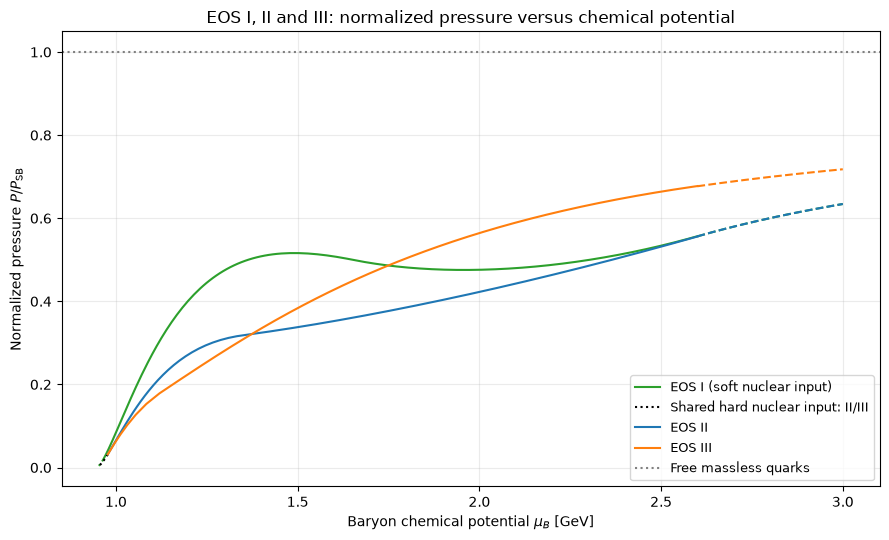

In [30]:
# Same reference pressure and units as the existing normalized comparison.
def pressure_SB(mu_B_MeV):
    mu_B_GeV = np.asarray(mu_B_MeV)/1000.0
    pressure_natural = 3/(4*np.pi**2)*(mu_B_GeV/3)**4
    return pressure_natural*1000/hbarc_GeVfm**3


n_pressure_I = np.linspace(n_begin_I, n_poly_end_I, 700)
n_pressure_II = np.linspace(n_begin, n_poly_end, 700)
n_pressure_III = np.linspace(n_begin, n_poly_end_III, 700)
mu_high_comparison = np.linspace(mu_end_III, 3000.0, 250)
mu_pressure_I = poly_mu_I(n_pressure_I)
mu_pressure_II = poly_mu_n(n_pressure_II)
mu_pressure_III = poly_mu_III(n_pressure_III)

plt.figure(figsize=(9, 5.5))

# EOS I: soft nuclear matter, two polytropes, then pQCD.
plt.plot(mu_chi_grid_I/1000, P_chi_grid_I/pressure_SB(mu_chi_grid_I),
         color='C2', linestyle=':')
plt.plot(mu_pressure_I/1000,
         poly_pressure_I(n_pressure_I)/pressure_SB(mu_pressure_I),
         color='C2', label='EOS I (soft nuclear input)')
plt.plot(mu_high_comparison/1000,
         pqcd_pressure_mu(mu_high_comparison, X=X_I)/pressure_SB(mu_high_comparison),
         '--', color='C2')

# EOS II and III retain the same shared hard nuclear branch.
plt.plot(mu_chi/1000, P_chi/pressure_SB(mu_chi),
         color='black', linestyle=':', label='Shared hard nuclear input: II/III')
plt.plot(mu_pressure_II/1000,
         poly_pressure_n(n_pressure_II)/pressure_SB(mu_pressure_II),
         color='C0', label='EOS II')
plt.plot(mu_high_comparison/1000,
         pqcd_pressure_mu(mu_high_comparison, X=1.2)/pressure_SB(mu_high_comparison),
         '--', color='C0')
plt.plot(mu_pressure_III/1000,
         poly_pressure_III(n_pressure_III)/pressure_SB(mu_pressure_III),
         color='C1', label='EOS III')
plt.plot(mu_high_comparison/1000,
         pqcd_pressure_mu(mu_high_comparison, X=X_III)/pressure_SB(mu_high_comparison),
         '--', color='C1')

plt.axhline(1, color='gray', linestyle=':', label='Free massless quarks')
plt.xlabel(r'Baryon chemical potential $\mu_B$ [GeV]')
plt.ylabel(r'Normalized pressure $P/P_{\rm SB}$')
plt.title('EOS I, II and III: normalized pressure versus chemical potential')
plt.grid(True, alpha=0.25)
plt.legend(fontsize=9)
plt.tight_layout()
plt.show()


### Comparison 2: mass-radius sequences for all three EOSs


Maximum mass = 2.422158276083814 M_sun
Radius = 12.676646240914048 km
Central pressure = 227.20114199003453 MeV/fm^3
EOS III sampled maximum mass = 2.2013560763122806 M_sun
EOS III radius at sampled maximum = 13.515861687457003 km
EOS III central pressure = 123.01915262620903 MeV/fm^3
EOS I sampled maximum mass = 2.023047876658527 M_sun
EOS I radius at sampled maximum = 9.898364234522122 km
EOS I central pressure = 586.3784297833926 MeV/fm^3


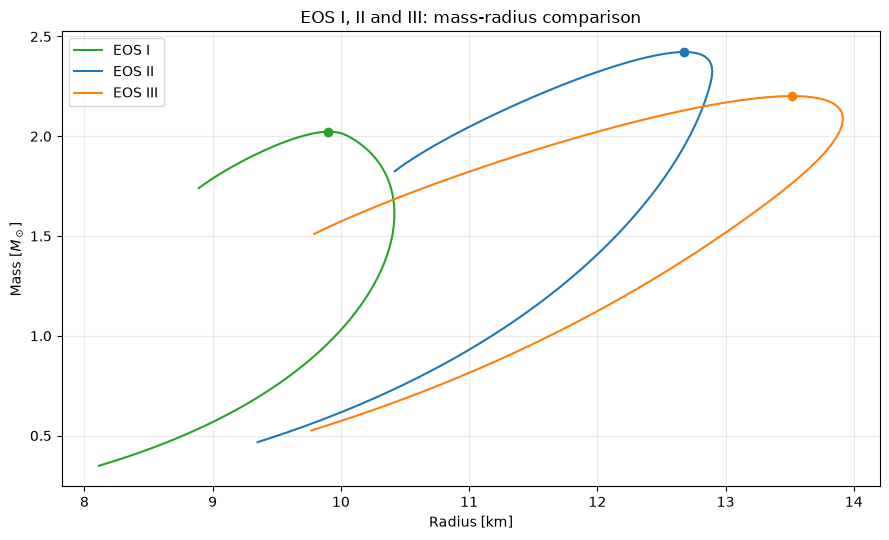

In [31]:
P_c_values = np.logspace(np.log10(10), np.log10(2500), 100)

M_values = []
R_values = []

for P_c in P_c_values:
    M,R = solve_star(P_c)
    M_values.append(M)
    R_values.append(R)

M_values = np.array(M_values)
R_values = np.array(R_values)

mask = np.isfinite(M_values) & np.isfinite(R_values)

M_good = M_values[mask]
R_good = R_values[mask]
P_good = P_c_values[mask]

imax = np.argmax(M_good)

M_max = M_good[imax]
R_max = R_good[imax]
P_c_max = P_good[imax]

print("Maximum mass =", M_max, "M_sun")
print("Radius =", R_max, "km")
print("Central pressure =", P_c_max, "MeV/fm^3")

# The EOS II sequence and variables above this line are retained unchanged.
# Use the same central pressures for the new EOS III sequence.
M_values_III = []
R_values_III = []
for central_pressure_III in P_c_values:
    mass_III, radius_III = solve_star_III(central_pressure_III)
    M_values_III.append(mass_III)
    R_values_III.append(radius_III)

M_values_III = np.array(M_values_III)
R_values_III = np.array(R_values_III)
imax_III = np.argmax(M_values_III)
P_c_max_III = P_c_values[imax_III]

print('EOS III sampled maximum mass =', M_values_III[imax_III], 'M_sun')
print('EOS III radius at sampled maximum =', R_values_III[imax_III], 'km')
print('EOS III central pressure =', P_c_max_III, 'MeV/fm^3')

# EOS I is evaluated at the SAME central pressures as EOS II and III.
M_values_I = []
R_values_I = []
for central_pressure_I in P_c_values:
    mass_I, radius_I = solve_star_I(central_pressure_I)
    M_values_I.append(mass_I)
    R_values_I.append(radius_I)
M_values_I = np.array(M_values_I)
R_values_I = np.array(R_values_I)
imax_I = np.argmax(M_values_I)
P_c_max_I = P_c_values[imax_I]

print('EOS I sampled maximum mass =', M_values_I[imax_I], 'M_sun')
print('EOS I radius at sampled maximum =', R_values_I[imax_I], 'km')
print('EOS I central pressure =', P_c_max_I, 'MeV/fm^3')

# Mass on the y axis; radius on the x axis.
plt.figure(figsize=(9, 5.5))
plt.plot(R_values_I, M_values_I, color='C2', label='EOS I')
plt.plot(R_good, M_good, color='C0', label='EOS II')
plt.plot(R_values_III, M_values_III, color='C1', label='EOS III')
plt.scatter(R_values_I[imax_I], M_values_I[imax_I], color='C2', zorder=3)
plt.scatter(R_good[imax], M_good[imax], color='C0', zorder=3)
plt.scatter(R_values_III[imax_III], M_values_III[imax_III], color='C1', zorder=3)
plt.xlabel('Radius [km]')
plt.ylabel(r'Mass [$M_\odot$]')
plt.title('EOS I, II and III: mass-radius comparison')
plt.grid(True, alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()


### Comparison 3: energy density and regions inside all three stars


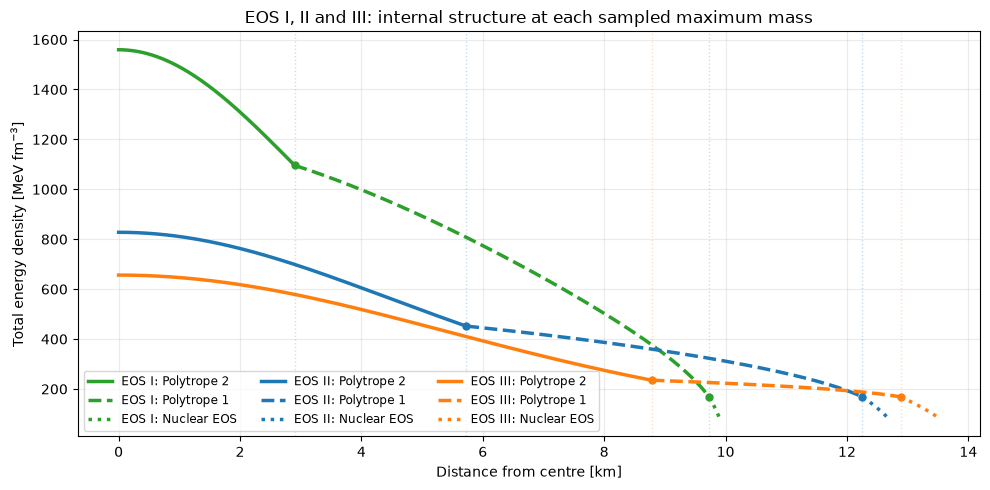

In [42]:
# Calculate each model's profile at its own sampled maximum mass.
M_profile_I, R_profile_I, solution_profile_I = solve_star_I(
    P_c_max_I, return_profile=True
)
r_comparison_I = solution_profile_I.t/1000
P_comparison_I = SI_to_MeV_fm3(solution_profile_I.y[1])
E_comparison_I = np.array([
    SI_to_MeV_fm3(full_e_density_I(max(pressure, P_surface_I)))
    for pressure in solution_profile_I.y[1]
])

# Preserve the EOS III profile variables used by the existing validation cell.
M_profile_III, R_profile_III, solution_profile_III = solve_star_III(
    P_c_max_III, return_profile=True
)
r_comparison_III = solution_profile_III.t/1000
P_comparison_III = SI_to_MeV_fm3(solution_profile_III.y[1])
E_comparison_III = np.array([
    SI_to_MeV_fm3(full_e_density_III(max(pressure, P_surface)))
    for pressure in solution_profile_III.y[1]
])

# Each model supplies its OWN nuclear and polytrope joining pressures.
profiles = [
    ('EOS I', r_comparison_I, P_comparison_I, E_comparison_I,
     P_transition_I, P_begin_I, P_qcd_start_I, 'C2'),
    ('EOS II', r_profile, P_profile, E_profile,
     P_transition, P_begin, P_qcd_start, 'C0'),
    ('EOS III', r_comparison_III, P_comparison_III, E_comparison_III,
     P_transition_III, P_begin, P_qcd_start_III, 'C1')
]

plt.figure(figsize=(10, 5))
for name, radius, pressure, energy, poly_join, nuclear_join, qcd_join, colour in profiles:
    radius = np.r_[0, radius]
    pressure = np.r_[pressure[0], pressure]
    energy = np.r_[energy[0], energy]

    # Include only boundaries that this particular star actually reaches.
    internal_pressures = [boundary for boundary in [qcd_join, poly_join, nuclear_join]
                          if pressure[-1] < boundary < pressure[0]]
    pressure_edges = [pressure[0]] + internal_pressures + [pressure[-1]]
    radius_edges = np.interp(pressure_edges, pressure[::-1], radius[::-1])

    for j in range(len(radius_edges) - 1):
        inner_radius, outer_radius = radius_edges[j:j+2]
        middle_pressure = (pressure_edges[j] + pressure_edges[j+1])/2
        if middle_pressure >= qcd_join:
            region_name, line_style = 'pQCD', '-.'
        elif middle_pressure >= poly_join:
            region_name, line_style = 'Polytrope 2', '-'
        elif middle_pressure >= nuclear_join:
            region_name, line_style = 'Polytrope 1', '--'
        else:
            region_name, line_style = 'Nuclear EOS', ':'

        inside = (radius > inner_radius) & (radius < outer_radius)
        region_radius = np.r_[inner_radius, radius[inside], outer_radius]
        region_energy = np.interp(region_radius, radius, energy)
        plt.plot(region_radius, region_energy, color=colour,
                 linestyle=line_style, linewidth=2.5,
                 label=f'{name}: {region_name}')

    for boundary_radius in radius_edges[1:-1]:
        plt.axvline(boundary_radius, color=colour, linestyle=':', alpha=0.25, linewidth=1)
        plt.scatter(boundary_radius, np.interp(boundary_radius, radius, energy),
                    color=colour, s=25, zorder=3)

plt.xlabel('Distance from centre [km]')
plt.ylabel(r'Total energy density [MeV fm$^{-3}$]')
plt.title('EOS I, II and III: internal structure at each sampled maximum mass')
plt.grid(True, alpha=0.25)
plt.legend(fontsize=8.5, ncol=3)
plt.tight_layout()
plt.show()


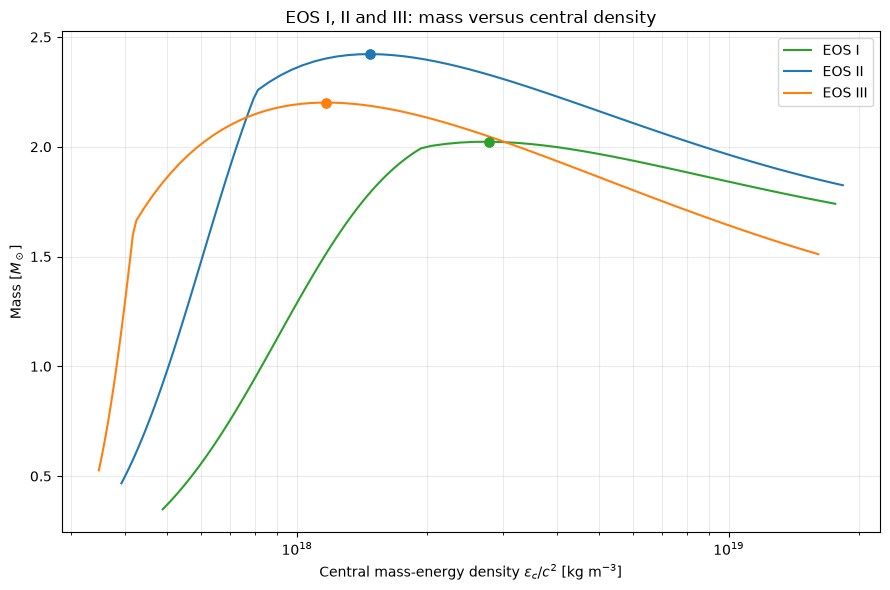

In [34]:
# Central mass-energy density [kg/m^3]
# Each entry contains:
# EOS name, central pressures, masses, energy-density function, colour.
sequences = [
    ("EOS I", P_c_values, M_values_I, full_e_density_I, "C2"),
    ("EOS II", P_good, M_good, full_e_density, "C0"),
    ("EOS III", P_c_values, M_values_III, full_e_density_III, "C1")
]

plt.figure(figsize=(9, 6))

for name, central_pressures, masses, energy_function, colour in sequences:

    # Convert central pressure [MeV/fm^3] to SI pressure,
    # calculate total energy density, then divide by c^2.
    central_densities = np.array([
        energy_function(MeV_fm3_to_SI(pressure)) / c**2
        for pressure in central_pressures
    ])

    plt.plot(
        central_densities,
        masses,
        color=colour,
        label=name
    )

    # Mark this EOS's largest sampled mass.
    peak_index = np.argmax(masses)

    plt.scatter(
        central_densities[peak_index],
        masses[peak_index],
        color=colour,
        s=45,
        zorder=3
    )

plt.xscale("log")
plt.xlabel(r"Central mass-energy density $\varepsilon_c/c^2$ [kg m$^{-3}$]")
plt.ylabel(r"Mass [$M_\odot$]")
plt.title("EOS I, II and III: mass versus central density")
plt.grid(True, which="both", alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()

### Comparison of EOS i Values to Literature Kurkela, Fraga et al (2014)

In [45]:
import numpy as np
import pandas as pd
from IPython.display import display

# EOS I: Table 2 of the 2014 paper.
# Columns: n/n0, P, energy density, mu_B [GeV], cs^2/c^2.
reference_I = np.array([
    [1.1,   2.163,  167.8, 0.9657, 0.041],
    [1.3,   3.687,  198.8, 0.9736, 0.058],
    [1.5,   5.822,  230.1, 0.9831, 0.079],
    [1.7,   8.681,  261.8, 0.9943, 0.10],
    [1.9,  12.38,   293.8, 1.007,  0.13],
    [2.1,  17.04,   326.2, 1.022,  0.16],
    [2.3,  22.79,   359.2, 1.038,  0.19],
    [2.5,  29.74,   392.7, 1.056,  0.22],
    [2.7,  38.02,   426.8, 1.076,  0.26],
    [2.9,  47.76,   461.6, 1.098,  0.30],
    [3.1,  59.09,   497.1, 1.121,  0.34],
    [3.3,  72.14,   533.3, 1.147,  0.38],
    [3.5,  87.05,   570.5, 1.174,  0.42],
    [3.7, 103.9,    608.5, 1.203,  0.47],
    [3.9, 123.0,    647.5, 1.235,  0.51],
    [4.1, 144.3,    687.6, 1.268,  0.55],
    [4.3, 167.9,    728.7, 1.303,  0.60],
    [4.5, 194.2,    771.0, 1.341,  0.64],
    [4.7, 223.1,    814.5, 1.380,  0.69],
    [4.9, 254.8,    859.3, 1.421,  0.73],
    [5.1, 289.5,    905.5, 1.464,  0.77],
    [5.3, 327.4,    953.1, 1.510,  0.82],
    [5.5, 368.5,   1002.0, 1.558,  0.86],
    [5.7, 413.0,   1053.0, 1.607,  0.90],
    [5.9, 455.3,   1105.0, 1.653,  0.30],
    [6.1, 471.1,   1158.0, 1.669,  0.30],
    [6.3, 486.9,   1212.0, 1.685,  0.29],
    [6.5, 502.8,   1266.0, 1.701,  0.29],
    [6.7, 518.6,   1321.0, 1.716,  0.29],
    [6.9, 534.5,   1376.0, 1.730,  0.29],
    [7.1, 550.3,   1431.0, 1.744,  0.28],
    [7.3, 566.2,   1487.0, 1.758,  0.28],
    [7.5, 582.1,   1544.0, 1.772,  0.28]
])

# Evaluate your EOS at exactly the published baryon densities.
n_test_I = reference_I[:, 0] * n0

P_my_I = poly_pressure_I(n_test_I)
E_my_I = poly_energy_I(n_test_I)
mu_my_I = poly_mu_I(n_test_I)

# Choose Gamma for each density and calculate cs^2/c^2 = Gamma*P/(mu*n).
gamma_test_I = np.where(
    n_test_I < n_transition_I, Gamma_I[0], Gamma_I[1]
)
cs2_my_I = gamma_test_I * P_my_I / (mu_my_I * n_test_I)

comparison_I = pd.DataFrame({
    "n/n0": reference_I[:, 0],
    "P paper": reference_I[:, 1],
    "P mine": P_my_I,
    "E paper": reference_I[:, 2],
    "E mine": E_my_I,
    "mu paper": 1000 * reference_I[:, 3],  # GeV to MeV
    "mu mine": mu_my_I,
    "cs2 paper": reference_I[:, 4],
    "cs2 mine": cs2_my_I
})

print("EOS I comparison")
with pd.option_context("display.max_rows", None, "display.max_columns", None):
    display(comparison_I.round(6))

EOS I comparison


,n/n0,P paper,P mine,E paper,E mine,mu paper,mu mine,cs2 paper,cs2 mine
0,1.1,2.163,2.163000,167.8,167.800200,965.7,965.700000,0.041,0.040622
1,1.3,3.687,3.686704,198.8,198.825035,973.6,973.614128,0.058,0.058110
2,1.5,5.822,5.821225,230.1,230.128527,983.1,983.123967,0.079,0.078751
3,1.7,8.681,8.680086,261.8,261.762467,994.3,994.274091,0.100,0.102450
4,1.9,12.380,12.379770,293.8,293.779993,1007.0,1007.104483,0.130,0.129071
5,2.1,17.040,17.039430,326.2,326.235465,1022.0,1021.651473,0.160,0.158444
6,2.3,22.790,22.780661,359.2,359.184354,1038.0,1037.948411,0.190,0.190373
7,2.5,29.740,29.727308,392.7,392.683160,1056.0,1056.026168,0.220,0.224638
8,2.7,38.020,38.005303,426.8,426.789332,1076.0,1075.913508,0.260,0.261003
9,2.9,47.760,47.742535,461.6,461.561214,1098.0,1097.637392,0.300,0.299221


### Comparison of EOS ii Values to Literature Kurkela, Fraga et al (2014)

In [46]:
import pandas as pd

n_lit = np.arange(1.1, 4.6, 0.2)

P_lit = np.array([
    3.542, 6.934, 12.33, 20.39, 31.89, 47.70,
    68.76, 96.16, 129.7, 141.2, 153.0, 164.8,
    176.8, 189.0, 201.2, 213.6, 226.1, 238.7
])

E_lit = np.array([
    168.5, 200.0, 232.3, 265.3, 299.6, 335.2,
    372.6, 412.1, 454.1, 497.7, 542.2, 587.4,
    633.4, 680.0, 727.3, 775.2, 823.8, 872.9
])

mu_lit = 1000*np.array([0.9775, 0.9951, 1.019, 1.051, 1.090, 1.140,1.199, 1.271, 1.351, 1.377, 1.402, 1.425,1.447, 1.468, 1.488, 1.507, 1.526, 1.544])

cs2_lit = np.array([
    0.083, 0.13, 0.20, 0.29, 0.39, 0.50,
    0.63, 0.76, 0.27, 0.26, 0.26, 0.26,
    0.26, 0.26, 0.26, 0.26, 0.26, 0.26
])
n_test = n_lit*n0

P_my = poly_pressure_n(n_test)
E_my = poly_energy_n(n_test)
mu_my = poly_mu_n(n_test)
cs2_my = poly_cs2_n(n_test)

comparison = pd.DataFrame({
    "n/n0": n_lit,
    "P paper": P_lit,
    "P mine": P_my,
    "E paper": E_lit,
    "E mine": E_my,
    "mu paper": mu_lit,
    "mu mine": mu_my,
    "cs2 paper": cs2_lit,
    "cs2 mine": cs2_my
})

comparison

,n/n0,P paper,P mine,E paper,E mine,mu paper,mu mine,cs2 paper,cs2 mine
0,1.1,3.542,3.542000,168.5,168.498000,977.5,977.500000,0.083,0.082785
1,1.3,6.934,6.933856,200.0,200.043585,995.1,995.083848,0.130,0.134706
2,1.5,12.330,12.327401,232.3,232.251761,1019.0,1019.079843,0.200,0.202668
3,1.7,20.390,20.391242,265.3,265.343849,1051.0,1050.496659,0.290,0.286955
4,1.9,31.890,31.891636,299.6,299.573492,1090.0,1090.345815,0.390,0.386877
5,2.1,47.700,47.692749,335.2,335.226742,1140.0,1139.641341,0.500,0.500817
6,2.3,68.760,68.756886,372.6,372.622138,1199.0,1199.399522,0.630,0.626381
7,2.5,96.160,96.144699,412.1,412.110774,1271.0,1270.638684,0.760,0.760637
8,2.7,129.700,129.685378,454.1,454.073963,1351.0,1351.294770,0.270,0.265476
9,2.9,141.200,141.246248,497.7,497.732385,1377.0,1377.109122,0.260,0.264155


### Comparison of EOS iii Values to Literature Kurkela, Fraga et al (2014)

In [47]:
import numpy as np
import pandas as pd
from IPython.display import display

# EOS III: Table 4 of the 2014 paper.
# Columns: n/n0, P, energy density, mu_B [GeV], cs^2/c^2.
reference_III = np.array([
    [1.1,   3.542, 168.5, 0.9775, 0.15],
    [1.3,  12.13,  200.4, 1.022,  0.42],
    [1.5,  34.81,  234.5, 1.122,  0.95],
    [1.7,  42.24,  270.9, 1.151,  0.19],
    [1.9,  49.44,  308.1, 1.176,  0.20],
    [2.1,  56.96,  346.2, 1.200,  0.20],
    [2.3,  64.79,  384.9, 1.222,  0.20],
    [2.5,  72.90,  424.4, 1.243,  0.21],
    [2.7,  81.29,  464.5, 1.263,  0.21],
    [2.9,  89.94,  505.2, 1.283,  0.21],
    [3.1,  98.84,  546.5, 1.301,  0.22],
    [3.3, 108.0,   588.5, 1.319,  0.22],
    [3.5, 117.4,   631.0, 1.336,  0.22],
    [3.7, 127.0,   674.0, 1.353,  0.22],
    [3.9, 136.8,   717.5, 1.369,  0.23]
])

# Evaluate your EOS at exactly the published baryon densities.
n_test_III = reference_III[:, 0] * n0

P_my_III = poly_pressure_III(n_test_III)
E_my_III = poly_energy_III(n_test_III)
mu_my_III = poly_mu_III(n_test_III)

# Choose Gamma for each density and calculate cs^2/c^2.
gamma_test_III = np.where(
    n_test_III < n_transition_III, Gamma_III[0], Gamma_III[1]
)
cs2_my_III = gamma_test_III * P_my_III / (mu_my_III * n_test_III)

comparison_III = pd.DataFrame({
    "n/n0": reference_III[:, 0],
    "P paper": reference_III[:, 1],
    "P mine": P_my_III,
    "E paper": reference_III[:, 2],
    "E mine": E_my_III,
    "mu paper": 1000 * reference_III[:, 3],  # GeV to MeV
    "mu mine": mu_my_III,
    "cs2 paper": reference_III[:, 4],
    "cs2 mine": cs2_my_III
})

print("EOS III comparison")
with pd.option_context("display.max_rows", None, "display.max_columns", None):
    display(comparison_III.round(6))

EOS III comparison


,n/n0,P paper,P mine,E paper,E mine,mu paper,mu mine,cs2 paper,cs2 mine
0,1.1,3.542,3.542000,168.5,168.498000,977.5,977.500000,0.15,0.151694
1,1.3,12.130,12.128354,200.4,200.381229,1022.0,1021.680689,0.42,0.420507
2,1.5,34.810,34.810291,234.5,234.477960,1122.0,1122.034379,0.95,0.952445
3,1.7,42.240,42.241133,270.9,270.892858,1151.0,1151.227908,0.19,0.190881
4,1.9,49.440,49.440935,308.1,308.136720,1176.0,1176.242289,0.20,0.195647
5,2.1,56.960,56.962709,346.2,346.156417,1200.0,1199.759304,0.20,0.199946
6,2.3,64.790,64.788097,384.9,384.907713,1222.0,1221.999484,0.20,0.203860
7,2.5,72.900,72.901329,424.4,424.352611,1243.0,1243.134851,0.21,0.207450
8,2.7,81.290,81.288678,464.5,464.458031,1263.0,1263.302567,0.21,0.210763
9,2.9,89.940,89.938057,505.2,505.194849,1283.0,1282.614022,0.21,0.213839


### Comparison of analytical eos to numerical eos in Hebeler et al. (2013
Compared the value of our derived analytical eos to the values of the numerical ones. We can say that the percentage difference/uncertainty is negligible so our analytical eos for low density holds.


In [36]:

# Columns: n/n0, pressure, total energy density
stiff_data = np.array([
    [0.5792,   0.696,   87.99],
    [0.7124,   1.150,  108.40],
    [0.7861,   1.473,  119.70],
    [0.8646,   1.880,  131.90],
    [0.9483,   2.392,  144.80],
    [1.0371,   3.028,  158.70],
    [1.1000,   3.542,  168.50],
    [1.2000,   5.240,  184.20],
    [1.3000,   7.512,  200.10],
    [1.4000,  10.480,  216.20],
    [1.5000,  14.300,  232.50],
    [1.6000,  20.390,  249.20],
    [1.7000,  28.470,  266.30],
    [1.8000,  38.980,  283.90],
    [1.9000,  52.490,  302.20],
    [2.0000,  69.590,  321.30],
    [2.1000,  80.560,  341.10],
    [2.2000,  92.630,  361.40],
    [2.3000, 105.800,  382.40],
    [2.4000, 120.200,  403.90],
    [2.5000, 135.900,  426.00],
    [2.6000, 152.900,  448.90],
    [2.7000, 171.200,  472.30],
    [2.8000, 190.900,  496.50],
    [2.9000, 212.100,  521.50],
    [3.0000, 234.800,  547.10],
    [3.1000, 259.100,  573.60],
    [3.2000, 285.000,  600.90],
    [3.3000, 312.600,  629.00]
])

# Select each column.
density_ratio = stiff_data[:, 0]
pressure_numerical = stiff_data[:, 1]
energy_numerical = stiff_data[:, 2]

In [37]:
# Keep only the low-density region, including 1.1 n0.
low_density_data = stiff_data[stiff_data[:, 0] <= 1.1]

density_ratio = low_density_data[:, 0]
pressure_numerical = low_density_data[:, 1]
energy_numerical = low_density_data[:, 2]

# Convert n/n0 into baryon density [fm^-3].
number_density = density_ratio * n0

# Evaluate your analytical EOS at the same densities.
pressure_analytical = np.array([
    combined_pressure_n(n) for n in number_density
])

energy_analytical = np.array([
    combined_energy_n(n) for n in number_density
])


In [38]:
pressure_difference = (
    100 * (pressure_analytical - pressure_numerical)
    / pressure_numerical
)

energy_difference = (
    100 * (energy_analytical - energy_numerical)
    / energy_numerical
)

comparison = pd.DataFrame({
    "n/n0": density_ratio,
    "P analytical": pressure_analytical,
    "P numerical": pressure_numerical,
    "P difference (%)": pressure_difference,
    "E analytical": energy_analytical,
    "E numerical": energy_numerical,
    "E difference (%)": energy_difference
})

display(comparison.round(4))

,n/n0,P analytical,P numerical,P difference (%),E analytical,E numerical,E difference (%)
0,0.5792,0.7084,0.696,1.7828,87.9681,87.99,-0.0249
1,0.7124,1.1629,1.150,1.1189,108.4070,108.40,0.0064
2,0.7861,1.4854,1.473,0.8416,119.7580,119.70,0.0484
3,0.8646,1.8911,1.880,0.5888,131.8844,131.90,-0.0118
4,0.9483,2.4000,2.392,0.3327,144.8581,144.80,0.0402
5,1.0371,3.0325,3.028,0.1501,158.6755,158.70,-0.0154
6,1.1000,3.5420,3.542,0.0000,168.4980,168.50,-0.0012


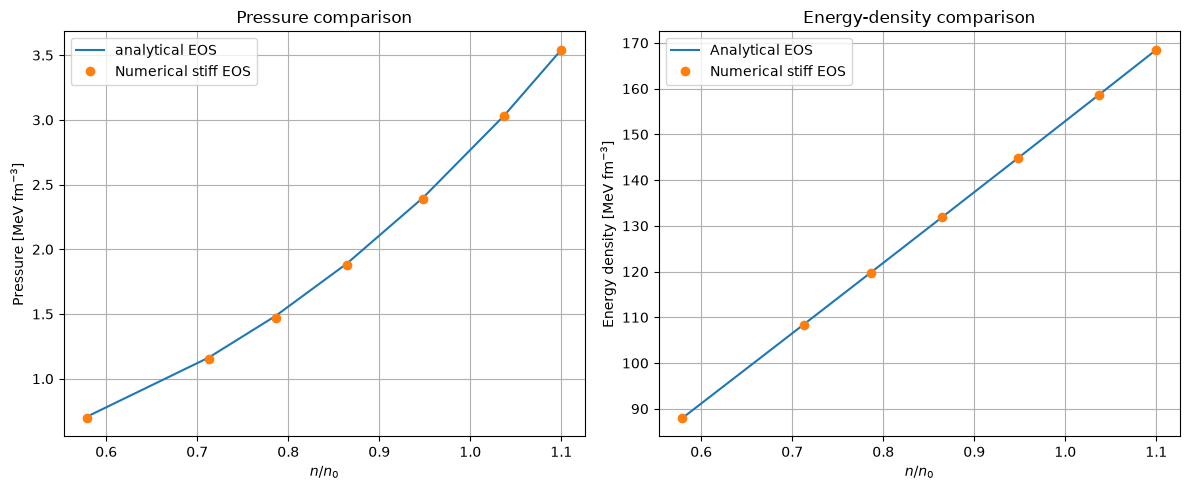

In [39]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Pressure comparison
axes[0].plot(
    density_ratio, pressure_analytical,
    label="analytical EOS"
)
axes[0].plot(
    density_ratio, pressure_numerical,
    "o", label="Numerical stiff EOS"
)

axes[0].set_xlabel(r"$n/n_0$")
axes[0].set_ylabel(r"Pressure [MeV fm$^{-3}$]")
axes[0].set_title("Pressure comparison")
axes[0].legend()
axes[0].grid()

# Total energy-density comparison
axes[1].plot(
    density_ratio, energy_analytical,
    label="Analytical EOS"
)
axes[1].plot(
    density_ratio, energy_numerical,
    "o", label="Numerical stiff EOS"
)

axes[1].set_xlabel(r"$n/n_0$")
axes[1].set_ylabel(r"Energy density [MeV fm$^{-3}$]")
axes[1].set_title("Energy-density comparison")
axes[1].legend()
axes[1].grid()

plt.tight_layout()
plt.show()

## Checks for the EOS II / EOS III comparison
These checks confirm that the nuclear EOS is shared, the segment join is
continuous, and the added solver agrees with the original solver below both
polytrope joins (where the two material models are identical). They also check
that tighter tolerances do not materially change an EOS III configuration.
No EOS II function or global parameter is replaced by these cells.

In [40]:
for pressure_test in np.linspace(P_chi_min*1.001, P_begin, 10):
    pressure_si_test = MeV_fm3_to_SI(pressure_test)
    np.testing.assert_allclose(full_e_density_III(pressure_si_test),
                               full_e_density(pressure_si_test), rtol=1e-12)

np.testing.assert_allclose(poly_mu_III(n_begin), mu_begin, rtol=1e-12)
np.testing.assert_allclose(poly_pressure_III(n_begin), P_begin, rtol=1e-12)
np.testing.assert_allclose(poly_mu_III(n_transition_III), mu_transition_III, rtol=1e-12)
np.testing.assert_allclose(kappa1_III*n_transition_III**Gamma_III[0],
                           kappa2_III*n_transition_III**Gamma_III[1], rtol=1e-12)

low_mass_II, low_radius_II = solve_star(2.0)
low_mass_III, low_radius_III = solve_star_III(2.0)
np.testing.assert_allclose([low_mass_II, low_radius_II],
                           [low_mass_III, low_radius_III], rtol=2e-5)

test_pressure_III = MeV_fm3_to_SI(P_c_max_III)
test_energy_III = full_e_density_III(test_pressure_III)
test_r0_III = 1e-3
test_m0_III = 4*np.pi*test_r0_III**3*test_energy_III/(3*c**2)
refined_solution_III = solve_ivp(
    tov_equations_III, [test_r0_III, 5e4], [test_m0_III, test_pressure_III],
    events=surface_event_III, rtol=1e-8, max_step=10
)
assert refined_solution_III.success and len(refined_solution_III.t_events[0]) == 1
refined_M_III = refined_solution_III.y_events[0][0][0]/M_sun
refined_R_III = refined_solution_III.t_events[0][0]/1000
np.testing.assert_allclose([M_profile_III, R_profile_III],
                           [refined_M_III, refined_R_III], rtol=5e-5)
assert np.all(np.diff(solution_profile_III.y[0]) >= -1e-6)
assert np.all(np.diff(solution_profile_III.y[1]) <= 0)
print('Passed: shared nuclear EOS, joins, low-density solver agreement and tolerance refinement.')
print('EOS II settings retained:', Gamma_regions, 'mu join =', mu_transition, 'X =', X_pqcd)
print('EOS III settings:', Gamma_III, 'mu join =', mu_transition_III, 'X =', X_III)

Passed: shared nuclear EOS, joins, low-density solver agreement and tolerance refinement.
EOS II settings retained: [4.021 1.195] mu join = 1350.0 X = 1.2
EOS III settings: [7.368 1.415] mu join = 1125.0 X = 1.9


## Additional EOS I checks
Check the soft anchor, polytrope continuity, finite interpolation domains,
low-density thermodynamics and numerical tolerance refinement. These checks
complement, rather than replace, the existing EOS II/III validation cell.
Sampled mass maxima remain grid-dependent and are not radial-mode analyses.

In [41]:
np.testing.assert_allclose([chiral_pressure_I(n_begin_I), chiral_mu_I(n_begin_I)],
                           [P_begin_I, mu_begin_I], rtol=1e-10)
np.testing.assert_allclose([poly_pressure_I(n_begin_I), poly_mu_I(n_begin_I)],
                           [P_begin_I, mu_begin_I], rtol=1e-12)
np.testing.assert_allclose(poly_mu_I(n_transition_I), mu_transition_I, rtol=1e-12)
np.testing.assert_allclose(kappa1_I*n_transition_I**Gamma_I[0],
                           kappa2_I*n_transition_I**Gamma_I[1], rtol=1e-12)
assert np.all(np.diff(P_chi_grid_I) > 0) and np.all(np.diff(E_chi_grid_I) > 0)
np.testing.assert_allclose(chi_E_of_P_I(P_chi_grid_I), E_chi_grid_I, rtol=1e-14)

# A few independent EOS I entries from the 2014 paper's Table 2.
reference_2014_I = np.array([
    [1.1, 2.163, 167.8],
    [1.5, 5.822, 230.1],
    [3.1, 59.09, 497.1],
    [5.1, 289.5, 905.5]
])
reference_n_I = reference_2014_I[:, 0]*n0
np.testing.assert_allclose(poly_pressure_I(reference_n_I),
                           reference_2014_I[:, 1], rtol=0.002)
np.testing.assert_allclose(poly_energy_I(reference_n_I),
                           reference_2014_I[:, 2], rtol=0.002)

# An independent finite difference checks P=n^2*d(E/n)/dn in the soft region.
for density_I in np.linspace(0.58*n0, 1.08*n0, 5):
    dn_I = density_I*1e-5
    derivative_I = (
        chiral_energy_I(density_I + dn_I)/(density_I + dn_I)
        - chiral_energy_I(density_I - dn_I)/(density_I - dn_I)
    )/(2*dn_I)
    np.testing.assert_allclose(density_I**2*derivative_I,
                               chiral_pressure_I(density_I), rtol=1e-6)

test_pc_I = MeV_fm3_to_SI(P_c_max_I)
test_ec_I = full_e_density_I(test_pc_I)
test_r0_I = 1e-3
test_m0_I = 4*np.pi*test_r0_I**3*test_ec_I/(3*c**2)
refined_solution_I = solve_ivp(
    tov_equations_I, [test_r0_I, 5e4], [test_m0_I, test_pc_I],
    events=surface_event_I, rtol=1e-8, max_step=10
)
assert refined_solution_I.success and len(refined_solution_I.t_events[0]) == 1
refined_M_I = refined_solution_I.y_events[0][0][0]/M_sun
refined_R_I = refined_solution_I.t_events[0][0]/1000
np.testing.assert_allclose([M_profile_I, R_profile_I],
                           [refined_M_I, refined_R_I], rtol=5e-5)
assert np.all(np.diff(solution_profile_I.y[0]) >= -1e-6)
assert np.all(np.diff(solution_profile_I.y[1]) <= 0)
np.testing.assert_allclose(SI_to_MeV_fm3(solution_profile_I.y[1, -1]),
                           P_chi_min_I, rtol=1e-10)

# Verify the old hard-EOS settings and coefficients have not been changed.
np.testing.assert_allclose(Gamma_regions, [4.021, 1.195], rtol=0, atol=0)
np.testing.assert_allclose(Gamma_III, [7.368, 1.415], rtol=0, atol=0)
np.testing.assert_allclose([alphaL, etaL],
                           [1.4641889049557169, 1.0214198935378929], rtol=1e-10)
assert mu_transition == 1350 and X_pqcd == 1.2
assert mu_transition_III == 1125 and X_III == 1.9
print('EOS I checks passed: anchor, joins, thermodynamics and solver refinement.')
print('EOS II/III hard nuclear parameters remain unchanged.')

EOS I checks passed: anchor, joins, thermodynamics and solver refinement.
EOS II/III hard nuclear parameters remain unchanged.
